# California Housing: Market Analysis for Retail Site Planning

**Business question.** A national retailer wants to know which California markets have the strongest customer base, so it can rank them for new stores and marketing spend. Home values and household income show how much local customers can spend.

**What this notebook answers**
1. Can we trust the data? (quality checks and cleaning)
2. What drives home values? (driver analysis)
3. Which customer segments and metro markets are the most valuable? (segmentation and KPIs)
4. What happens to predicted home value if local income rises? (what-if analysis with a model)
5. What should the business do? (recommendations and limitations)

**Data.** 1990 California census, 20,640 *block groups* (small neighbourhoods of about 600–3,000 people). Each row is one neighbourhood, **not** one house. Source file: `data/housing.csv`.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
IMG = Path("images"); IMG.mkdir(exist_ok=True)

raw = pd.read_csv("data/housing.csv")
print(raw.shape)
raw.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.00,880.00,129.00,322.00,126.00,8.33,"452,600.00",NEAR BAY
1,-122.22,37.86,21.00,"7,099.00","1,106.00","2,401.00","1,138.00",8.30,"358,500.00",NEAR BAY
2,-122.24,37.85,52.00,"1,467.00",190.00,496.00,177.00,7.26,"352,100.00",NEAR BAY
3,-122.25,37.85,52.00,"1,274.00",235.00,558.00,219.00,5.64,"341,300.00",NEAR BAY
4,-122.25,37.85,52.00,"1,627.00",280.00,565.00,259.00,3.85,"342,200.00",NEAR BAY


### Column guide (plain English)
| Column | Meaning |
|---|---|
| `longitude`, `latitude` | Location of the neighbourhood |
| `housing_median_age` | Typical age of the homes (years) |
| `total_rooms`, `total_bedrooms` | Rooms and bedrooms summed over the whole neighbourhood |
| `population`, `households` | People and households living there |
| `median_income` | Typical household income, **in units of $10,000** (3.5 = $35,000) |
| `median_house_value` | Typical home value in US dollars (**target**) |
| `ocean_proximity` | Location type: `<1H OCEAN`, `INLAND`, `NEAR OCEAN`, `NEAR BAY`, `ISLAND` |

## 2. Data quality checks
Before analysing anything, check whether the numbers can be trusted.

In [2]:
checks = {
    "Rows": len(raw),
    "Duplicate rows": raw.duplicated().sum(),
    "Missing total_bedrooms": raw["total_bedrooms"].isna().sum(),
    "Home value capped at $500,001": (raw["median_house_value"] >= 500_001).sum(),
    "Home age capped at 52 years": (raw["housing_median_age"] >= 52).sum(),
    "Income capped at 15.0001 ($150k)": (raw["median_income"] >= 15.0001).sum(),
    "ISLAND rows (tiny category)": (raw["ocean_proximity"] == "ISLAND").sum(),
    "Rooms per household > 20 (likely resorts/odd)": ((raw.total_rooms / raw.households) > 20).sum(),
    "People per household > 10 (likely dorms/prisons)": ((raw.population / raw.households) > 10).sum(),
}
quality = pd.DataFrame.from_dict(checks, orient="index", columns=["count"])
quality["% of rows"] = (quality["count"] / len(raw) * 100).round(2)
quality

,count,% of rows
Rows,20640,100.00
Duplicate rows,0,0.00
Missing total_bedrooms,207,1.00
"Home value capped at $500,001",965,4.68
Home age capped at 52 years,1273,6.17
Income capped at 15.0001 ($150k),49,0.24
ISLAND rows (tiny category),5,0.02
Rooms per household > 20 (likely resorts/odd),69,0.33
People per household > 10 (likely dorms/prisons),37,0.18


**What the checks tell us**
- **No duplicates**, and only **1%** of `total_bedrooms` is missing. That's low, so filling the gaps is safe.
- **Capped values:** the census cut off top home values at $500,001 (about 4.8% of rows), so the true values in the richest areas are **higher** than shown. Any average for wealthy segments is therefore an *underestimate*.
- **ISLAND has only 5 rows**, too few to report as its own segment. It's kept in the model and grouped with `NEAR OCEAN` for segment reporting.
- A small number of neighbourhoods have extreme rooms or people per household (resorts, dorms, institutions). They're flagged, not deleted, and medians are used so they don't distort results.

## 3. Cleaning and new columns

In [3]:
df = raw.copy()

# 1) Fill missing bedrooms with a bedrooms-per-room ratio (more realistic than one fixed number)
ratio = (df["total_bedrooms"] / df["total_rooms"]).median()
df["bedrooms_filled"] = df["total_bedrooms"].isna()
df["total_bedrooms"] = df["total_bedrooms"].fillna((df["total_rooms"] * ratio).round())

# 2) Business-friendly columns
df["income_usd"] = df["median_income"] * 10_000
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["people_per_household"] = df["population"] / df["households"]
df["value_to_income"] = df["median_house_value"] / df["income_usd"]   # affordability KPI

# 3) Flags instead of deletions
df["value_capped"] = df["median_house_value"] >= 500_001
df["location"] = df["ocean_proximity"].replace({"ISLAND": "NEAR OCEAN"})

# 4) Income bands (quintiles = 5 equal-sized groups)
df["income_band"] = pd.qcut(df["income_usd"], 5,
                            labels=["Q1 Lowest", "Q2", "Q3", "Q4", "Q5 Highest"])

# 5) Metro market: nearest big city within 60 km, else 'Rest of CA'
metros = {"Los Angeles": (34.05, -118.24), "San Francisco": (37.77, -122.42),
          "San Diego": (32.72, -117.16), "San Jose": (37.34, -121.89),
          "Sacramento": (38.58, -121.49), "Fresno": (36.74, -119.79)}
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))
dist = pd.DataFrame({m: haversine_km(df.latitude, df.longitude, *xy) for m, xy in metros.items()})
df["metro"] = np.where(dist.min(axis=1) <= 60, dist.idxmin(axis=1), "Rest of CA")

df.to_csv("data/housing_clean.csv", index=False)
print("Filled bedrooms:", df["bedrooms_filled"].sum(), "| ratio used:", round(ratio, 3))
df["metro"].value_counts()

Filled bedrooms: 207 | ratio used: 0.203


metro
Los Angeles      7354
Rest of CA       5835
San Francisco    2601
San Jose         1554
San Diego        1551
Sacramento       1086
Fresno            659
Name: count, dtype: int64

**Why these choices**
- **Bedrooms filled with a ratio (bedrooms ≈ rooms × 0.20)** instead of one fixed number, so large neighbourhoods get proportionally more bedrooms.
- **Flags instead of deleting rows**, so no customers are dropped from the market. We just know which numbers to treat with care.
- **Income in dollars and quintiles**, so stakeholders can read the numbers without converting them.
- **Metro market** turns raw coordinates into something a retail planner uses: a trade area around a major city.

## 4. KPIs used in this analysis

| KPI | Formula | Why a retailer cares |
|---|---|---|
| Households | sum of `households` | Number of potential customers |
| Median household income | median of `income_usd` | Spending power |
| Median home value | median of `median_house_value` | Wealth and affluence signal |
| Value-to-income ratio | home value ÷ income | Affordability. A high ratio means housing eats the budget |
| Income pool | Σ households × income | Total yearly income in a market, a rough size of the customer wallet |

In [4]:
kpi = lambda g: pd.Series({
    "neighbourhoods": len(g),
    "households": g["households"].sum(),
    "median_income_usd": g["income_usd"].median(),
    "median_home_value": g["median_house_value"].median(),
    "value_to_income": g["value_to_income"].median(),
    "income_pool_$bn": (g["households"] * g["income_usd"]).sum() / 1e9,
})
overall = kpi(df).to_frame("All California")
overall

,All California
neighbourhoods,"20,640.00"
households,"10,310,499.00"
median_income_usd,"35,348.00"
median_home_value,"179,700.00"
value_to_income,4.95
income_pool_$bn,401.04


## 5. Where are home values highest? (map)

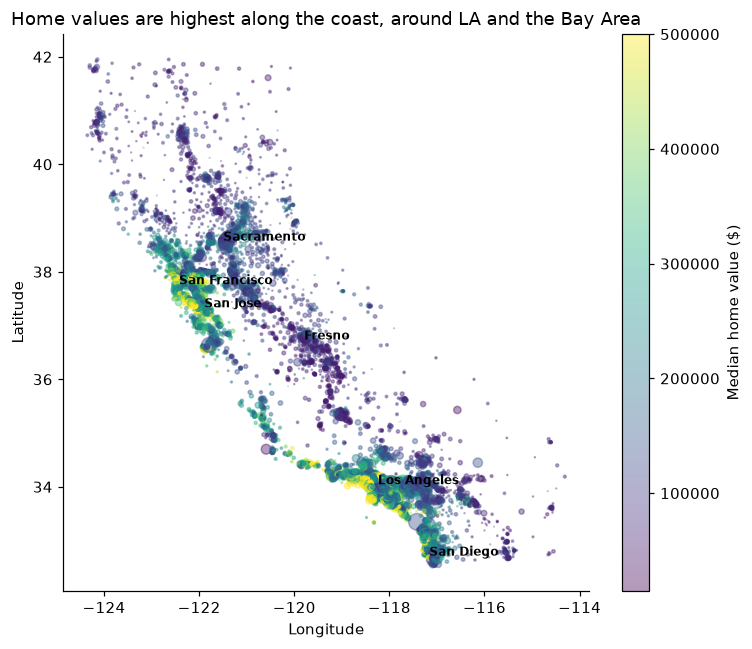

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(df["longitude"], df["latitude"], c=df["median_house_value"], cmap="viridis",
                s=df["population"] / 300, alpha=0.4)
for m, (lat, lon) in metros.items():
    ax.annotate(m, (lon, lat), fontsize=8, weight="bold")
fig.colorbar(sc, label="Median home value ($)")
ax.set(title="Home values are highest along the coast, around LA and the Bay Area",
       xlabel="Longitude", ylabel="Latitude")
fig.tight_layout(); fig.savefig(IMG / "01_map_home_values.png"); plt.show()

## 6. What drives home value?

In [6]:
num_cols = ["income_usd", "rooms_per_household", "bedrooms_per_room", "people_per_household",
            "housing_median_age", "population", "households", "latitude", "longitude"]
drivers = df[num_cols + ["median_house_value"]].corr()["median_house_value"].drop("median_house_value")
drivers = drivers.sort_values(key=abs, ascending=False).to_frame("correlation_with_value")
drivers

,correlation_with_value
income_usd,0.69
bedrooms_per_room,-0.25
rooms_per_household,0.15
latitude,-0.14
housing_median_age,0.11
households,0.07
longitude,-0.05
population,-0.02
people_per_household,-0.02


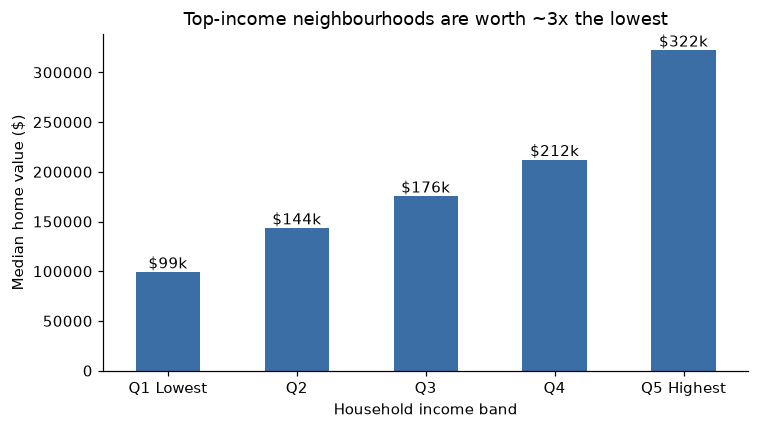

,median_income_usd,median_home_value,households
income_band,,,
Q1 Lowest,"19,038.00","99,200.00","1,827,800.00"
Q2,"27,411.00","143,500.00","2,110,248.00"
Q3,"35,352.00","175,500.00","2,162,973.00"
Q4,"44,375.00","212,200.00","2,138,043.00"
Q5 Highest,"61,592.50","322,300.00","2,071,435.00"


In [7]:
by_band = df.groupby("income_band", observed=True).agg(
    median_income_usd=("income_usd", "median"),
    median_home_value=("median_house_value", "median"),
    households=("households", "sum"))
ax = by_band["median_home_value"].plot.bar(rot=0, figsize=(7, 4), color="#3b6ea5")
ax.set(title="Top-income neighbourhoods are worth ~3x the lowest", ylabel="Median home value ($)", xlabel="Household income band")
ax.bar_label(ax.containers[0], labels=[f"${v/1000:,.0f}k" for v in by_band["median_home_value"]])
plt.tight_layout(); plt.savefig(IMG / "02_value_by_income_band.png"); plt.show()
by_band

## 7. Segmentation: income band × location

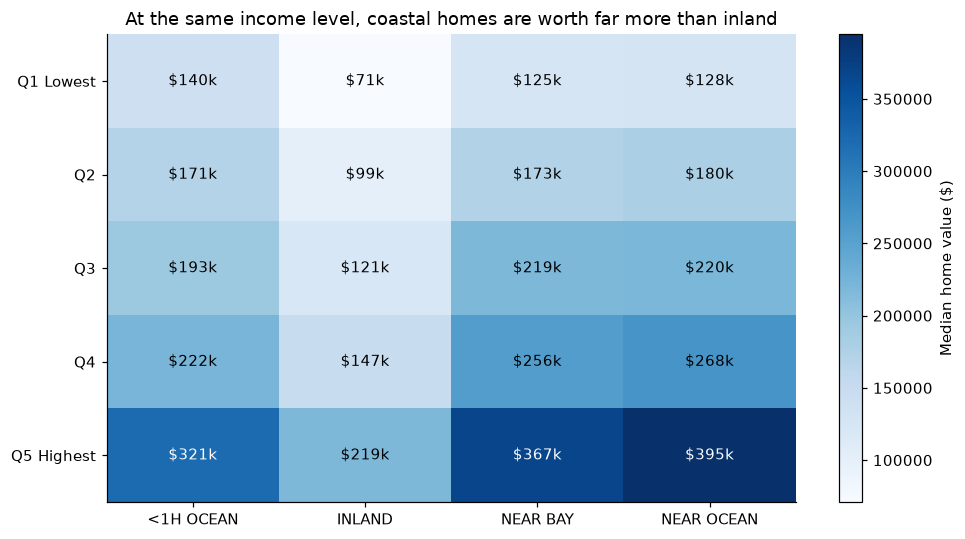

location,<1H OCEAN,INLAND,NEAR BAY,NEAR OCEAN
income_band,,,,
Q1 Lowest,"139,550.00","71,000.00","125,000.00","128,250.00"
Q2,"170,800.00","99,100.00","173,400.00","179,500.00"
Q3,"193,250.00","121,000.00","218,850.00","219,900.00"
Q4,"221,700.00","146,900.00","256,300.00","268,300.00"
Q5 Highest,"320,800.00","218,700.00","367,100.00","394,800.00"


In [8]:
seg = df.pivot_table(index="income_band", columns="location", values="median_house_value",
                     aggfunc="median", observed=True)
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(seg.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(seg.shape[1]), seg.columns); ax.set_yticks(range(seg.shape[0]), seg.index)
for i in range(seg.shape[0]):
    for j in range(seg.shape[1]):
        v = seg.values[i, j]
        ax.text(j, i, f"${v/1000:,.0f}k", ha="center", va="center", color="white" if v > 300_000 else "black")
ax.set_title("At the same income level, coastal homes are worth far more than inland")
fig.colorbar(im, label="Median home value ($)")
plt.tight_layout(); plt.savefig(IMG / "03_segment_heatmap.png"); plt.show()
seg

In [9]:
loc_kpis = df.groupby("location").apply(kpi, include_groups=False).sort_values("median_home_value", ascending=False)
loc_kpis

,neighbourhoods,households,median_income_usd,median_home_value,value_to_income,income_pool_$bn
location,,,,,,
NEAR BAY,"2,290.00","1,118,931.00","38,186.50","233,800.00",5.85,46.37
NEAR OCEAN,"2,663.00","1,333,691.00","36,429.00","229,500.00",6.11,53.34
<1H OCEAN,"9,136.00","4,730,118.00","38,750.00","214,850.00",5.44,197.51
INLAND,"6,551.00","3,127,759.00","29,877.00","108,500.00",3.64,103.82


## 8. Market ranking: which metro areas to prioritise?

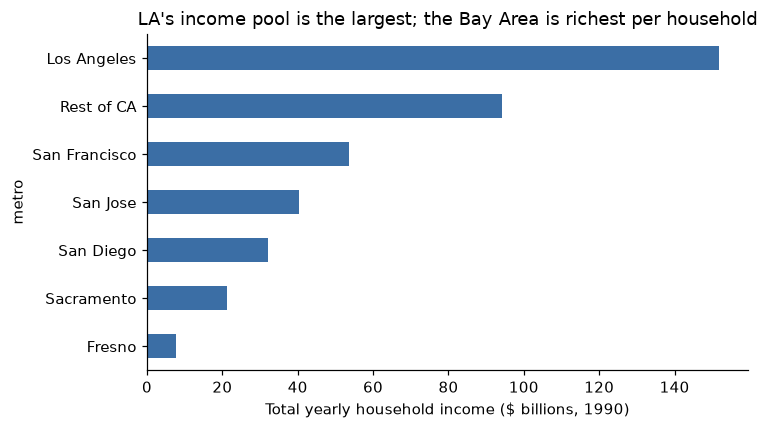

,neighbourhoods,households,median_income_usd,median_home_value,value_to_income,income_pool_$bn,share_of_CA_households_%
metro,,,,,,,
Los Angeles,"7,354.00","3,735,968.00","37,068.50","209,200.00",5.64,151.89,36.23
Rest of CA,"5,835.00","2,766,055.00","30,341.00","118,800.00",4.02,94.20,26.83
San Francisco,"2,601.00","1,271,445.00","39,110.00","244,100.00",5.87,53.58,12.33
San Jose,"1,554.00","808,515.00","48,858.00","266,800.00",5.56,40.25,7.84
San Diego,"1,551.00","849,384.00","35,437.00","168,900.00",4.91,32.03,8.24
Sacramento,"1,086.00","607,284.00","32,978.50","129,400.00",3.82,21.27,5.89
Fresno,659.00,"271,848.00","25,921.00","73,800.00",2.95,7.81,2.64


In [10]:
metro_kpis = df.groupby("metro").apply(kpi, include_groups=False)
metro_kpis["share_of_CA_households_%"] = metro_kpis["households"] / df["households"].sum() * 100
metro_kpis = metro_kpis.sort_values("income_pool_$bn", ascending=False)
ax = metro_kpis["income_pool_$bn"].plot.barh(figsize=(7, 4), color="#3b6ea5")
ax.invert_yaxis()
ax.set(title="LA's income pool is the largest; the Bay Area is richest per household",
       xlabel="Total yearly household income ($ billions, 1990)")
plt.tight_layout(); plt.savefig(IMG / "04_metro_income_pool.png"); plt.show()
metro_kpis

## 9. Predictive model
Goal: estimate a neighbourhood's home value from its features. This lets us run **what-if** scenarios and rank which factors matter most.

- **Train/test split:** 80/20, *stratified by income*, so both parts have the same mix of rich and poor areas (same as the original coursework).
- **Models compared:** a simple *business baseline* (median value of the neighbourhood's income band × location segment), Linear Regression and Random Forest.

In [11]:
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, mean_absolute_percentage_error

features_num = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms",
                "population", "households", "median_income",
                "rooms_per_household", "bedrooms_per_room", "people_per_household"]
features_cat = ["ocean_proximity"]

split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(split.split(df, df["income_band"]))
train, test = df.iloc[train_idx], df.iloc[test_idx]
X_train, y_train = train[features_num + features_cat], train["median_house_value"]
X_test, y_test = test[features_num + features_cat], test["median_house_value"]

prep = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), features_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), features_cat)])

def score(name, y_true, y_pred):
    return {"model": name, "R2": r2_score(y_true, y_pred), "MAE_$": mean_absolute_error(y_true, y_pred),
            "RMSE_$": root_mean_squared_error(y_true, y_pred), "MAPE_%": mean_absolute_percentage_error(y_true, y_pred) * 100}

seg_median = train.groupby(["income_band", "location"], observed=True)["median_house_value"].median()
baseline_pred = test.set_index(["income_band", "location"]).index.map(seg_median).to_numpy()

lin = Pipeline([("prep", prep), ("model", LinearRegression())]).fit(X_train, y_train)
rf = Pipeline([("prep", prep), ("model", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))]).fit(X_train, y_train)

results = pd.DataFrame([
    score("Segment-median baseline", y_test, baseline_pred),
    score("Linear Regression", y_test, lin.predict(X_test)),
    score("Random Forest", y_test, rf.predict(X_test)),
]).set_index("model")
results

,R2,MAE_$,RMSE_$,MAPE_%
model,,,,
Segment-median baseline,0.52,"55,377.69","79,691.11",27.45
Linear Regression,0.65,"49,043.83","68,066.05",28.65
Random Forest,0.82,"32,110.41","48,723.13",18.06


**How to read the metrics**
- **R²**: the share of the differences in home value that the model explains (1.0 = perfect).
- **MAE**: the typical error in dollars.
- **MAPE**: the typical error as a percentage of the home value.

### Which features matter most? (permutation importance)
Shuffle one feature at a time and measure how much worse the model gets. The bigger the drop, the more the model relies on that feature.

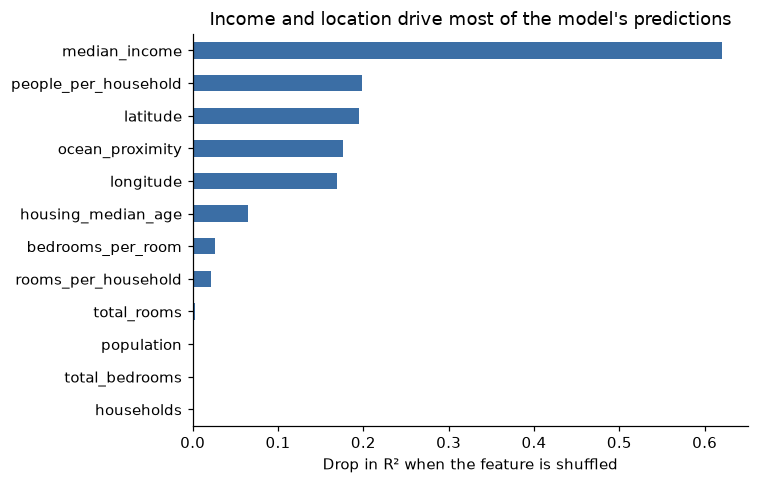

median_income          0.62
people_per_household   0.20
latitude               0.20
ocean_proximity        0.18
longitude              0.17
housing_median_age     0.07
bedrooms_per_room      0.03
rooms_per_household    0.02
total_rooms            0.00
population             0.00
total_bedrooms         0.00
households             0.00
dtype: float64

In [12]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(rf, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1, scoring="r2")
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
ax = imp.plot.barh(figsize=(7, 4.5), color="#3b6ea5")
ax.set(title="Income and location drive most of the model's predictions", xlabel="Drop in R² when the feature is shuffled")
plt.tight_layout(); plt.savefig(IMG / "05_feature_importance.png"); plt.show()
imp.sort_values(ascending=False).round(3)

## 10. What-if analysis: what if local household income rises?

In [13]:
base_pred = rf.predict(X_test)
rows = []
for uplift_k in [5, 10, 20]:
    X_new = X_test.copy()
    X_new["median_income"] = X_new["median_income"] + uplift_k / 10   # income is in $10k units
    delta = rf.predict(X_new) - base_pred
    rows.append({"income_rise": f"+${uplift_k}k", "avg_change_in_value_$": delta.mean(),
                 "avg_change_%": (delta / base_pred).mean() * 100})
whatif = pd.DataFrame(rows).set_index("income_rise")
whatif

,avg_change_in_value_$,avg_change_%
income_rise,,
+$5k,"13,721.04",7.63
+$10k,"30,613.22",17.51
+$20k,"71,864.85",42.52


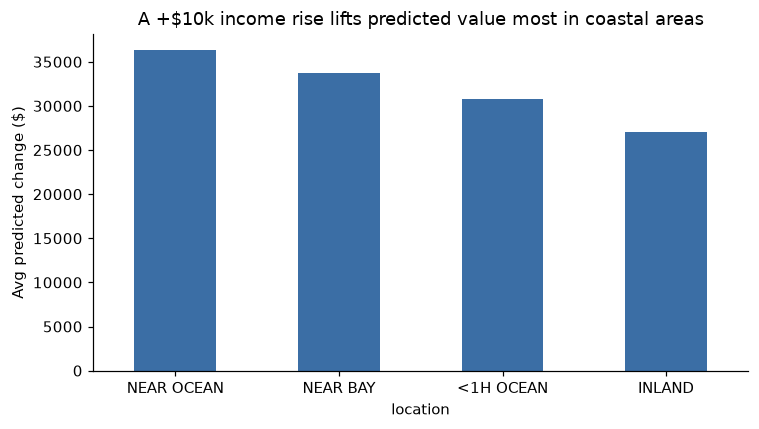

,avg_change_$_for_+10k_income
location,
NEAR OCEAN,"36,318.97"
NEAR BAY,"33,717.82"
<1H OCEAN,"30,732.46"
INLAND,"27,100.52"


In [14]:
X_new = X_test.copy(); X_new["median_income"] += 1.0
delta = pd.Series(rf.predict(X_new) - base_pred, index=X_test.index)
whatif_seg = delta.groupby(test["location"]).mean().sort_values(ascending=False).to_frame("avg_change_$_for_+10k_income")
ax = whatif_seg.iloc[:, 0].plot.bar(rot=0, figsize=(7, 4), color="#3b6ea5")
ax.set(title="A +$10k income rise lifts predicted value most in coastal areas", ylabel="Avg predicted change ($)")
plt.tight_layout(); plt.savefig(IMG / "06_whatif_income.png"); plt.show()
whatif_seg

> **Caution:** this shows what the model *predicts*, not proof that income *causes* higher home values. It's useful for comparing scenarios, not as a guarantee.

## 11. Key findings
1. **Income is the #1 driver of home value.** Correlation is 0.69, and income is also the model's most important feature: shuffling it drops R² by 0.62. The top-income neighbourhoods are worth **3.3x** the lowest ($322k vs $99k median).
2. **Location is the #2 driver.** The median inland home is worth **$108.5k**, against **$215k–$234k** in coastal areas. Even at the *same* income, coastal homes are worth far more: top-income inland areas ($219k) are worth about the same as *middle*-income near-ocean areas ($220k).
3. **Los Angeles is the biggest market by far.** It has **36% of California's households** and a **$152bn** yearly income pool, 2.8x the San Francisco area.
4. **The San Jose area has the richest customers.** It has the highest median household income ($48.9k) and home value ($267k).
5. **Affordability differs sharply.** Coastal homes cost **5.4–6.1x** yearly income, against **3.6x** inland (Sacramento 3.8x, Fresno 3.0x). Inland households have more budget left after housing.
6. **The model is reliable enough for scenario planning.** The Random Forest explains **82%** of the variation in home value (R² 0.82). Its typical error is **$32k (18%)**, **42% lower** than the simple segment-average baseline ($55k).
7. **What-if:** a **+$10k** rise in local household income lifts predicted home value by about **$30.6k (+17.5%)** on average. The effect is larger near the ocean (+$36k) than inland (+$27k).
8. **The data is mostly clean but capped.** 1% of bedroom counts were missing and filled. 4.7% of home values are capped at $500k, so the richest areas are understated.

## 12. Recommendations
1. **Prioritise Los Angeles for volume.** It has the largest customer base and income pool, so it suits high-traffic, everyday-essentials stores and the bulk of marketing spend.
2. **Lean premium in San Jose and San Francisco.** Incomes are the highest, but housing takes a big share of income (about 5.6–5.9x). A mix of premium and strong-value products fits customers who earn well but feel squeezed by housing costs.
3. **Treat inland markets (Sacramento, rest of California) as value-led growth markets.** Incomes are lower, but housing pressure is lighter. *Hypothesis to test:* lower property costs could make new stores cheaper to run there.
4. **Plan with segments, not averages.** The income band × location view shows that the same income buys very different housing on the coast vs inland. Use it to tailor assortment and pricing by trade area.
5. **Next step before any real decision:** repeat this analysis with current census (ACS) data and the company's own store sales to confirm the patterns still hold.

## 13. Limitations
- **Old data (1990).** Today's dollar levels are very different. The *patterns* (income and coastal location drive value) are what carry over.
- **Capped values.** Home values above $500k and incomes above $150k were cut off, so the richest areas are understated.
- **Neighbourhood averages, not individual homes or customers.** Findings describe areas, not people.
- **The what-if results are predictions, not cause and effect.**
- **Metro areas use a simple 60 km radius around 6 cities**, a rough proxy for real trade areas.